In [1]:

%load_ext autoreload
%autoreload 2

import time

import matplotlib.pyplot as plt

from config import (
    STANDART_DIVIATONS_NOISE, REALESATION_COUNT, SNR_VALUES, SENSOR_COUNTS,
    M, R, FIX_SIGMA
)
from experiment_stats import (mae_vs_snr, mae_vs_sensor_count)


Радиус решетки: 1
Количество датчиков: 5
Время рассчёта 3.65 сек.
Уменьшение ошибки в 4.69 раз


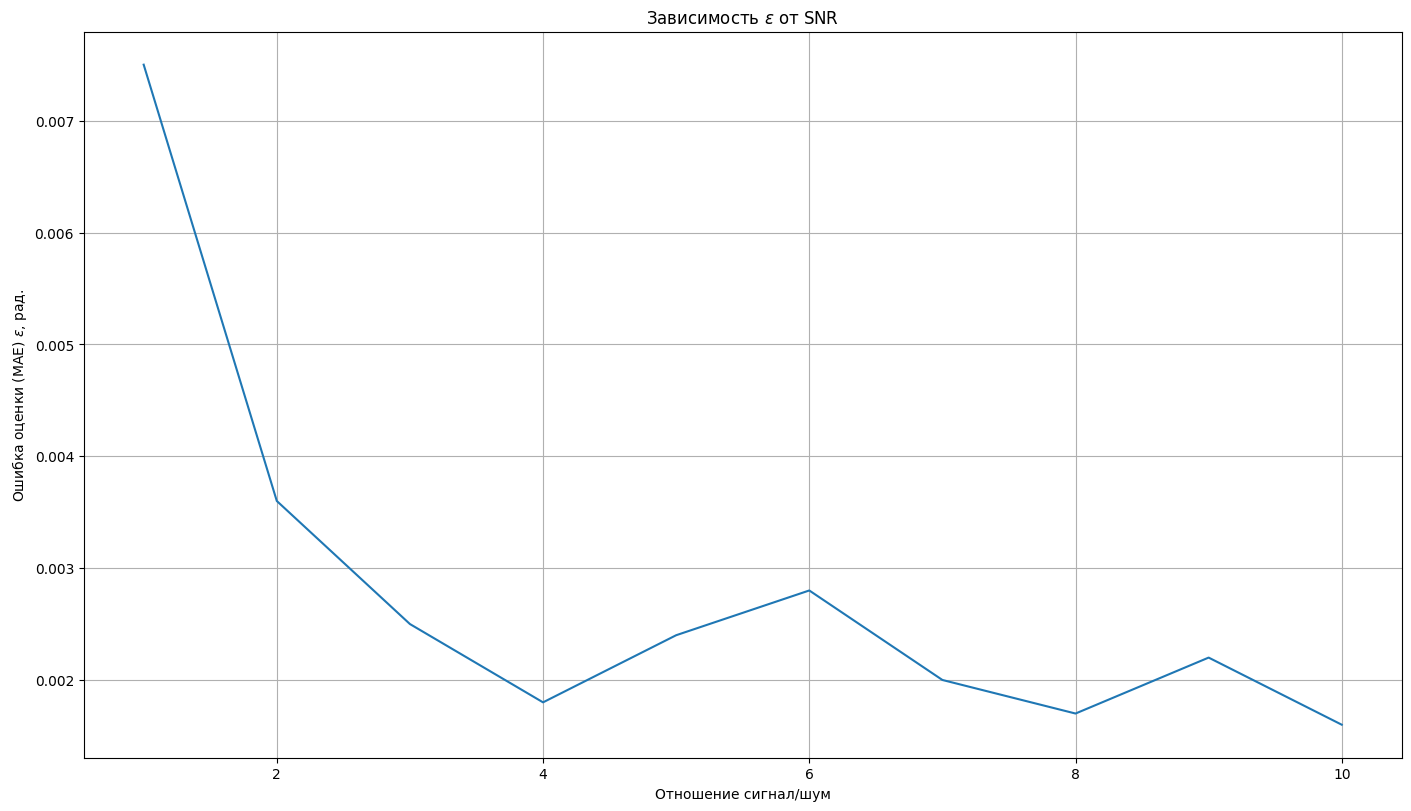

In [2]:
start_time = time.perf_counter()
snr_maes = mae_vs_snr(STANDART_DIVIATONS_NOISE, REALESATION_COUNT, M, R)
end_time = time.perf_counter()
delta_time = end_time - start_time
print("Радиус решетки:", R)
print("Количество датчиков:", M)
print(f"Время рассчёта {round(delta_time,2)} сек.")
print("Уменьшение ошибки в",round(snr_maes[0]/snr_maes[-1],2), "раз")

fig, ax = plt.subplots(1,1, figsize = (14,8), constrained_layout = True)
ax.plot(SNR_VALUES, snr_maes)
ax.set_xlabel("Отношение сигнал/шум")
ax.set_ylabel("Ошибка оценки (МАЕ) " + r"$\varepsilon$" + ", рад.")
ax.set_title("Зависимость " + r"$\varepsilon$" + " от SNR")
ax.grid(True)



Время рассчёта 2.49 сек.
Уменьшение ошибки в 4.09 раз


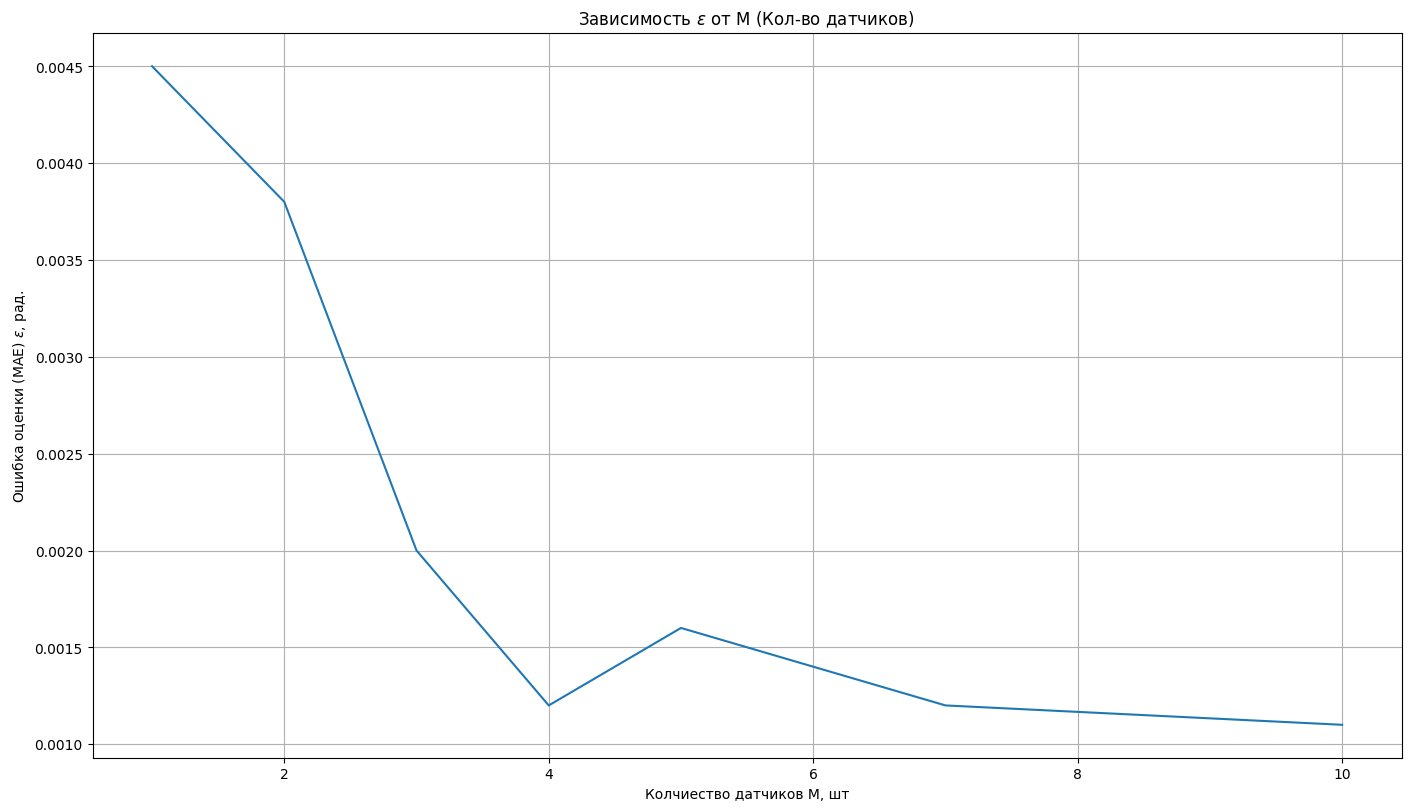

In [3]:

start_time = time.perf_counter()
sensor_maes = mae_vs_sensor_count(FIX_SIGMA, REALESATION_COUNT, SENSOR_COUNTS, R)
end_time = time.perf_counter()
delta_time = end_time - start_time
print(f"Время рассчёта {round(delta_time,2)} сек.")
print("Уменьшение ошибки в",round(sensor_maes[0]/sensor_maes[-1],2), "раз")

fig, ax = plt.subplots(1,1, figsize = (14,8), constrained_layout = True)
ax.plot(SENSOR_COUNTS, sensor_maes)
ax.set_xlabel("Колчиество датчиков M, шт")
ax.set_ylabel("Ошибка оценки (МАЕ) " + r"$\varepsilon$" + ", рад.")
ax.set_title("Зависимость " + r"$\varepsilon$" + " от M (Кол-во датчиков) ")
ax.grid(True)